# Quantum Range-Doppler Algorithm (Simplified, Didactic Version)
The Quantum Range-Doppler Algorithm is a method to analyze FMCW signals in a structured way that makes it easier to extract meaningful information about targets. FMCW contain both fast-time (range) and slow-time (along-track) variations, encoding the distance and relative velocity of objects in the scene.

By representing the signal as a quantum state and applying quantum operations such as the Fourier transform, matched filtering, and range cell migration compensation (RCMC), this algorithm converts raw, complex waveforms into a Range-Doppler map. In this map:

Peaks along the range axis indicate the distance of a target from the radar.
Peaks along the Doppler axis indicate the relative velocity of the target.

The advantage of using this structured, step-by-step quantum approach is that it allows the phases of the signal to combine constructively, so the peaks corresponding to targets stand out clearly from noise. Once the Range-Doppler map is computed, it becomes much easier to identify targets, measure their distance and velocity, and analyze their motion, even in the presence of noise or signal distortions.

In short, this algorithm transforms complex FMCW signals into a representation where physical information is directly accessible, providing a clear and intuitive way to extract range and velocity information from radar measurements.
This notebook explains a simplified quantum Range-Doppler (RD) algorithm, for didactic purposes:

- **Step 1:** QFT on fast-time (t)  
- **Step 2:** Matched Filter applied **after fast-time QFT**  
- **Step 3:** QFT on slow-time (η)  
- **Step 4:** RCMC applied **after slow-time QFT**  
---

## 1. Quantum Signal Encoding

$$
|\psi_0\rangle =  \sum_{t,\eta} s(t,\eta) |t\rangle \otimes |\eta\rangle
$$

- $s(t,\eta)$ encodes signal sampling

---

## 2. Fast-Time QFT

$$
|\psi_1\rangle = \text{QFT}_t |\psi_0\rangle
$$

- Converts fast-time phases into **range bins**.  
- Peaks correspond to **estimated target range**.

---

## 3. Matched Filter (Applied After QFT_t)

$$
|\psi_2\rangle = U_\text{MF} |\psi_1\rangle
= \sum_{f_r,\eta} e^{i \phi_F(f_r)} \hat{s}(f_r,\eta) |f_r\rangle \otimes |\eta\rangle
$$

- Here we **apply phase corrections in the frequency domain**.  
- Purpose: **align the peak in range**.

---

## 4. Slow-Time QFT

$$
|\psi_3\rangle = \text{QFT}_\eta |\psi_2\rangle
=  \sum_{f_r,f_d} e^{i \phi_F(f_r)} S(f_r,f_d) |f_r\rangle \otimes |f_d\rangle
$$

- Transforms slow-time η → Doppler bins.

---

## 5. RCMC (Applied After QFT_η)

$$
|\psi_4\rangle = U_\text{RCMC} |\psi_3\rangle
= \sum_{f_r,f_d} e^{i \phi_c(f_r,f_d)} e^{i \phi_F(f_r)} S(f_r,f_d) |f_r\rangle \otimes |f_d\rangle
$$

- Compensates **range migration** in the Doppler map.  
- Aligns the target peak across slow-time bins.

---

## 6. Peak Extraction

- Maximum amplitude gives **estimated range and Doppler**:

```python
peak_idx = np.unravel_index(np.argmax(np.abs(S)), S.shape)
range_bin_peak, doppler_bin_peak = peak_idx


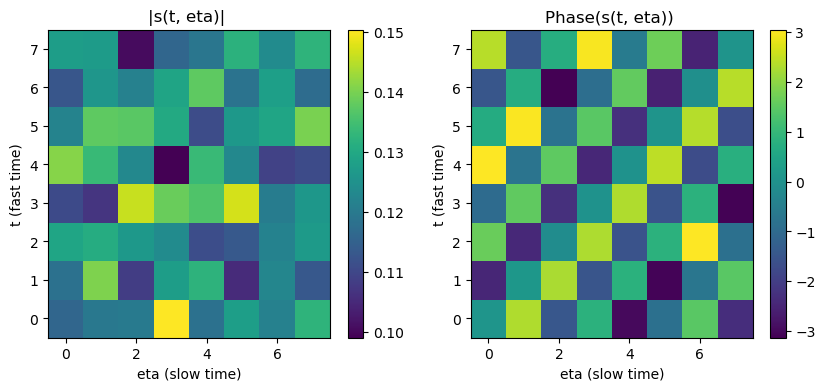

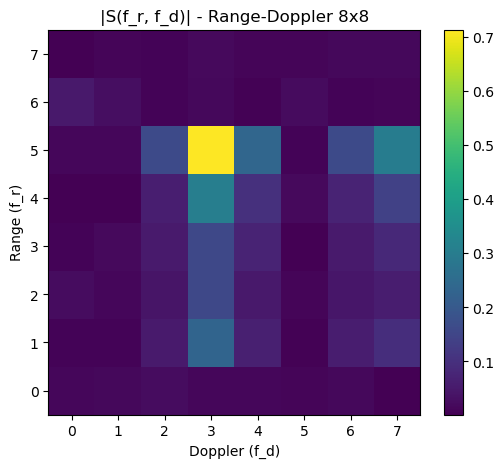

Bin of the peak: Range=5, Doppler=3


In [48]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

# -----------------------------
# Parameters
# -----------------------------
Nt = 8
Neta = 8
n_t = int(np.log2(Nt))   # 3 qubit for  range
n_eta = int(np.log2(Neta))  # 3 qubit for Doppler
n_qubits_total = n_t + n_eta  # 6 qubit
noise_level = 0.1    # level of rumor

# Target chosen
R_bin = 5             # bin range target
v_bin = 3             # bin Doppler target

# -----------------------------
# 1. SAR signal
# -----------------------------
s = np.zeros((Nt, Neta), dtype=complex)
for t in range(Nt):
    for eta in range(Neta):
        phase = 2*np.pi * (R_bin * t / Nt + v_bin * eta / Neta)
        s[t, eta] = np.exp(1j*phase)

# Gaussian noise
s += noise_level * (np.random.randn(Nt, Neta) + 1j*np.random.randn(Nt, Neta))

# Normalization
s /= np.linalg.norm(s)

# -----------------------------
# 2. Input
# -----------------------------
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.imshow(np.abs(s), aspect='auto',origin='lower')
plt.title("|s(t, eta)| ")
plt.xlabel("eta (slow time)")
plt.ylabel("t (fast time)")
plt.colorbar()

plt.subplot(1,2,2)
plt.imshow(np.angle(s), aspect='auto',origin='lower')
plt.title("Phase(s(t, eta)) ")
plt.xlabel("eta (slow time)")
plt.ylabel("t (fast time)")
plt.colorbar()
plt.show()

# -----------------------------
# 3. Flatten and quantistic state
# -----------------------------
def qft(n, do_swap=True):
    """QFT su n qubit. Se do_swap=True, applica lo swap finale."""
    qc = QuantumCircuit(n)
    for j in range(n):
        qc.h(j)
        for k in range(j+1, n):
            qc.cp(np.pi/2**(k-j), k, j)
    if do_swap:
        for i in range(n//2):
            qc.swap(i, n-i-1)
    return qc

# Flatten  (range less significant, Doppler more significant)
state_vector = s.T.flatten()

# Circuit
qc = QuantumCircuit(n_qubits_total)
qc.initialize(state_vector, range(n_qubits_total))

# -----------------------------
# 3.QFT on range (fast time) - no swap 
# -----------------------------
qc.append(qft(n_t, do_swap=False), range(n_t))

# -----------------------------
# 4.Matched filter 
# -----------------------------
for q in range(n_t):
    theta = -2*np.pi * R_bin * (2**q) / Nt  
    qc.p(theta, q)

# -----------------------------
# 5.QFT on Doppler (slow time) - swap necessary
# -----------------------------
qc.append(qft(n_eta, do_swap=True), range(n_t, n_t+n_eta))

# -----------------------------
# 6. Simulation
# -----------------------------
final_state = Statevector.from_instruction(qc)
result = final_state.data.reshape((Nt, Neta))

# -----------------------------
# 7. Visualization of Range-Doppler map
# -----------------------------
plt.figure(figsize=(6,5))
plt.imshow(np.abs(result), aspect='auto', origin='lower')
plt.title("|S(f_r, f_d)| - Range-Doppler 8x8")
plt.xlabel("Doppler (f_d)")
plt.ylabel("Range (f_r)")
plt.colorbar()
plt.show()

# -----------------------------
# 8. Extraction of the peak
# -----------------------------
peak_idx = np.unravel_index(np.argmax(np.abs(result)), result.shape)
range_bin_peak, doppler_bin_peak = peak_idx
print(f"Bin of the peak: Range={range_bin_peak}, Doppler={doppler_bin_peak}")

          
